# Alerta Golpe: análise exploratória

O que esta análise responde:

1. Quantas mensagens há de cada rótulo, categoria e origem.
2. Se o tamanho do texto separa golpe de legítima.
3. Quais termos e bigramas aparecem mais em cada classe.
4. Quanto link, valor e palavra de urgência aparecem em cada classe.
5. **Quais diferenças são de canal, não de conteúdo** — ou seja, existem só porque o
   golpe veio de SMS e a legítima veio de e-mail. Esses sinais entram na avaliação
   "sem sinais de canal" na etapa do modelo.

A base é pequena e balanceada de propósito. Veja as limitações em `data/README.md`.

## Principais achados

**1. O emoji não é sinal de golpe, é marca de uma fonte.** Emoji separa muito bem as
classes nesta base (49% dos golpes contra 5% das legítimas), e seria um atalho
tentador. Mas a quebra por fonte, na seção 5, mostra o contrário do que o número
sugere: emoji está em **70% dos anúncios de grupo de Telegram**, em **0% dos golpes
que chegam por SMS** e em **10% das legítimas de e-mail**. No caso de uso do app, que
é alguém colando um SMS, o golpe não traz emoji e a mensagem legítima da loja traz.
Aprender emoji seria aprender ao contrário do mundo real.

**2. O link separa por formato, não por conteúdo.** 63% dos golpes contra 17% das
legítimas. Os e-mails legítimos chegaram sem URL no corpo, porque o endereço estava
atrás de botão HTML.

**3. Urgência e valor são sinais de conteúdo** e devem sustentar a previsão.

**4. Código de verificação não separa** (9% contra 11%): é negativo difícil, não sinal.

In [1]:
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.feature_extraction.text import CountVectorizer

from alerta_golpe.dataset import load_messages
from alerta_golpe.preprocessing import normalize_text

pd.set_option("display.max_colwidth", 80)
plt.rcParams["figure.figsize"] = (8, 4)
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3

mensagens = load_messages()
mensagens["normalizado"] = mensagens["texto"].map(normalize_text)
mensagens["tamanho"] = mensagens["texto"].str.len()
mensagens["palavras"] = mensagens["texto"].str.split().str.len()
print(f"{len(mensagens)} mensagens, {mensagens['grupo'].nunique()} grupos")

139 mensagens, 74 grupos


## 1. Contagens

In [2]:
contagem = mensagens.groupby(["rotulo", "origem"]).agg(
    mensagens=("id", "size"), grupos=("grupo", "nunique")
)
contagem

mensagens  grupos
rotulo   origem                      
golpe    real              57      26
legitima real              42      29
         sintetica         40      19

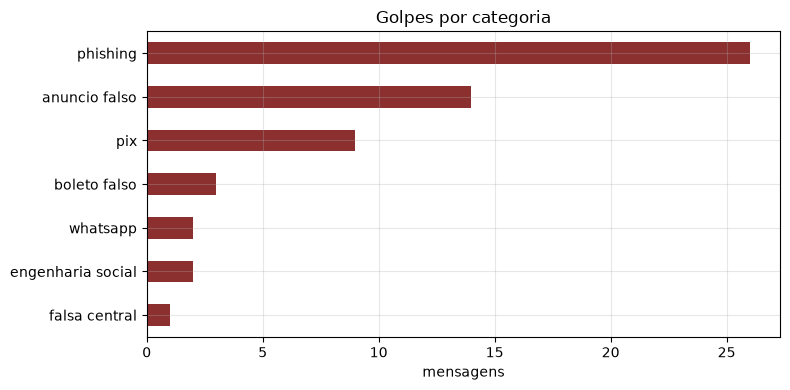

In [3]:
por_categoria = mensagens[mensagens["rotulo"] == "golpe"].groupby("categoria").size().sort_values()
eixo = por_categoria.plot.barh(color="#8b2f2f")
eixo.set_title("Golpes por categoria")
eixo.set_xlabel("mensagens")
eixo.set_ylabel("")
plt.tight_layout()
plt.show()

O rótulo está equilibrado: 57 golpes contra 82 legítimas. Por grupo, que é a contagem
que importa para a divisão entre treino e teste, são 26 modelos de golpe e 48 de
legítima.

Entre os golpes, phishing domina. Não é só o nosso recorte: link falso é o formato
mais barato de aplicar em escala.

## 2. Tamanho do texto

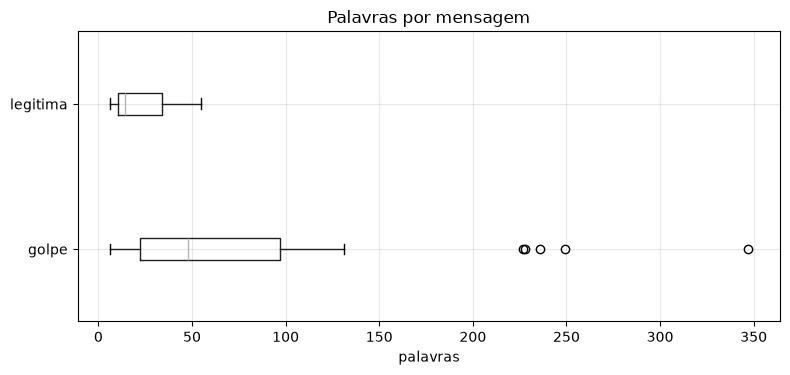

,count,25%,50%,75%,max
rotulo,,,,,
golpe,57.0,22.00,48.0,97.0,347.0
legitima,82.0,10.25,14.0,34.0,55.0


In [4]:
eixo = mensagens.boxplot(column="palavras", by="rotulo", vert=False)
eixo.set_title("Palavras por mensagem")
eixo.set_xlabel("palavras")
eixo.set_ylabel("")
plt.suptitle("")
plt.tight_layout()
plt.show()

mensagens.groupby("rotulo")["palavras"].describe()[["count", "25%", "50%", "75%", "max"]]

In [5]:
mensagens.groupby(["rotulo", "origem"])["palavras"].median()

rotulo    origem   
golpe     real         48.0
legitima  real         34.0
          sintetica    10.0
Name: palavras, dtype: float64

O golpe é mais longo que a legítima na mediana. Mas parte disso é canal e parte é
origem: as sintéticas que eu escrevi são conversas curtas, e puxam a mediana das
legítimas para baixo. Comparando só as reais a diferença encolhe, o que indica que
tamanho é um sinal fraco e contaminado — não vale apostar nele.

## 3. Termos e bigramas mais frequentes

In [6]:
def mais_frequentes(textos: pd.Series, ngram: tuple[int, int], quantos: int = 15) -> pd.Series:
    # lowercase=False preserva os marcadores: <LINK> não pode virar a palavra "link".
    vetor = CountVectorizer(ngram_range=ngram, lowercase=False, min_df=2)
    matriz = vetor.fit_transform(textos)
    soma = pd.Series(matriz.sum(axis=0).A1, index=vetor.get_feature_names_out())
    return soma.sort_values(ascending=False).head(quantos)


golpes = mensagens.loc[mensagens["rotulo"] == "golpe", "normalizado"]
legitimas = mensagens.loc[mensagens["rotulo"] == "legitima", "normalizado"]

pd.DataFrame(
    {
        "golpe": mais_frequentes(golpes, (1, 1)).index,
        "legitima": mais_frequentes(legitimas, (1, 1)).index,
    }
)

,golpe,legitima
0,de,de
1,VALOR,voce
2,no,para
3,pix,sua
4,seu,em
5,00,do
6,000,um
7,em,seu
8,emprestimo,que
9,nao,com


In [7]:
pd.DataFrame(
    {
        "golpe": mais_frequentes(golpes, (2, 2)).index,
        "legitima": mais_frequentes(legitimas, (2, 2)).index,
    }
)

,golpe,legitima
0,000 00,voce pode
1,auxilio brasil,sua conta
2,emprestimo de,em LINK
3,sua conta,codigo de
4,via pix,sua fatura
5,de VALOR,conta do
6,no pv,foi voce
7,VALOR vai,as informacoes
8,vai 000,em um
9,entrada de,de rastreio


Os bigramas do golpe mostram o roteiro: `auxilio brasil`, `via pix`, `emprestimo de`,
`entrada de`, `no valor`. Os da legítima são operacionais: `sua fatura`, `codigo de`,
`este codigo`, `de rastreio`, `seu pedido`.

`VALOR` e `LINK` aparecem no topo do golpe. Valor é sinal de conteúdo; o link é o que
a seção 5 põe em dúvida.

## 4. Link, valor e urgência

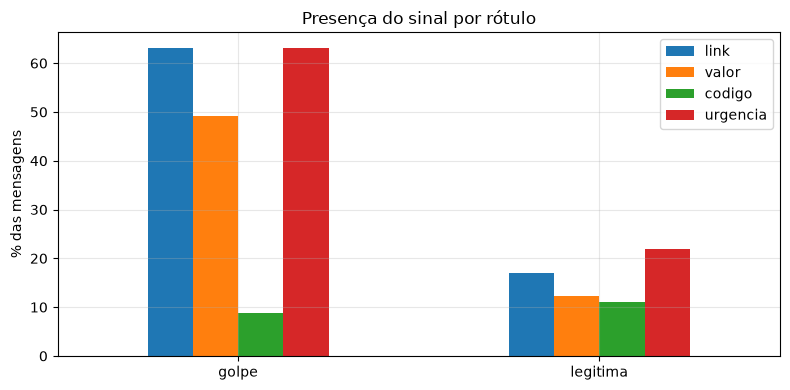

,link,valor,codigo,urgencia
rotulo,,,,
golpe,63.0,49.0,9.0,63.0
legitima,17.0,12.0,11.0,22.0


In [8]:
URGENCIA = (
    r"urgente|imediat|agora|hoje|ultimo aviso|prazo|vence|bloque|suspens"
    r"|cancelad|evite|atencao|nao perca|limitad|24 horas|irregular|pendencia"
)

SINAIS = {
    "link": r"<LINK>",
    "valor": r"<VALOR>",
    "codigo": r"<CODIGO>",
    "urgencia": URGENCIA,
}

presenca = pd.DataFrame(
    {
        nome: mensagens.groupby("rotulo")["normalizado"].apply(
            lambda col, p=padrao: col.str.contains(p, case=False, regex=True).mean()
        )
        for nome, padrao in SINAIS.items()
    }
)
eixo = (presenca * 100).plot.bar(rot=0)
eixo.set_title("Presença do sinal por rótulo")
eixo.set_ylabel("% das mensagens")
eixo.set_xlabel("")
plt.tight_layout()
plt.show()

(presenca * 100).round(0)

Urgência e valor separam bem e são sinais de conteúdo: o golpe precisa de pressa e
precisa falar de dinheiro. Código aparece parecido nas duas classes, porque código de
verificação legítimo é comum — e é justamente o que o golpista pede para você repassar.

O link é o caso problemático, e a próxima seção explica por quê.

## 5. Sinais de canal

Os golpes desta base vêm de SMS e de grupos de mensageria. As legítimas reais vêm de
e-mail. Qualquer diferença que exista só por causa disso é atalho: o modelo acerta o
teste e erra na vida real, onde a legítima também chega por SMS.

Abaixo, os candidatos a sinal de canal.

In [9]:
CANAL = {
    "palavra e-mail": r"\be-?mails?\b",
    "anexo": r"\banexo\b",
    "PDF": r"\bpdf\b",
    "botao": r"\bbot[aã]o\b",
    "emoji": "[\U0001f300-\U0001faff\u2600-\u27bf]",
    "link": r"<LINK>",
}

canal = pd.DataFrame(
    {
        nome: mensagens.groupby("rotulo")["texto"].apply(
            lambda col, p=padrao: col.str.contains(p, case=False, regex=True).mean()
        )
        for nome, padrao in CANAL.items()
    }
)
(canal * 100).round(0)

,palavra e-mail,anexo,PDF,botao,emoji,link
rotulo,,,,,,
golpe,5.0,0.0,0.0,2.0,49.0,63.0
legitima,6.0,2.0,2.0,0.0,5.0,17.0


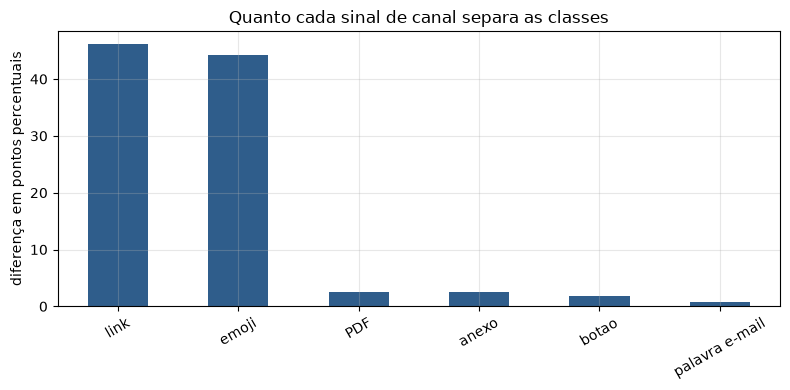

link              46.0
emoji             44.0
PDF                2.0
anexo              2.0
botao              2.0
palavra e-mail     1.0
dtype: float64

In [10]:
diferenca = (canal.loc["golpe"] - canal.loc["legitima"]).abs().sort_values(ascending=False)
eixo = (diferenca * 100).plot.bar(rot=30, color="#2f5d8b")
eixo.set_title("Quanto cada sinal de canal separa as classes")
eixo.set_ylabel("diferença em pontos percentuais")
eixo.set_xlabel("")
plt.tight_layout()
plt.show()

diferenca.mul(100).round(0)

In [11]:
# De onde vem o emoji: se for de uma fonte só, é artefato dela, não sinal de golpe.
fonte_curta = (
    mensagens["fonte"]
    .str.replace(r"^https://github.*", "golpe: anuncio de grupo", regex=True)
    .str.replace(r"^https://www\..*", "golpe: SMS de checagem", regex=True)
    .str.replace(r"^exemplo.*", "legitima: sintetica", regex=True)
    .str.replace(r"^e-mail.*", "legitima: e-mail", regex=True)
)
tem_emoji = mensagens["texto"].str.contains("[\U0001f300-\U0001faff\u2600-\u27bf]")
mensagens.assign(fonte_curta=fonte_curta, tem_emoji=tem_emoji).groupby("fonte_curta").agg(
    com_emoji_pct=("tem_emoji", lambda coluna: round(coluna.mean() * 100)),
    mensagens=("id", "size"),
)

,com_emoji_pct,mensagens
fonte_curta,,
golpe: SMS de checagem,0,17
golpe: anuncio de grupo,70,40
legitima: e-mail,10,42
legitima: sintetica,0,40


### Conclusão da seção

Dois sinais separam as classes sem serem conteúdo de golpe:

1. **`<LINK>`**, com 46 pontos de diferença (63% contra 17%). Os e-mails chegaram sem
   URL no corpo, porque o endereço estava atrás de botão HTML. A adaptação de canal
   descrita no data card levou 6 legítimas reais com link para o teste, mas a
   diferença continua grande.
2. **emoji**, com 44 pontos. A tabela por fonte mostra que não é sinal de golpe nem
   exatamente de canal: é artefato de **uma fonte**. Emoji está em 70% dos anúncios
   de grupo de Telegram, em **0%** dos golpes de SMS, e em 10% das legítimas de
   e-mail. Ou seja, no golpe que chega por SMS, que é o caso de uso do app, emoji não
   aparece — mas o modelo pode aprender que aparece.

As **palavras de e-mail** (`e-mail`, `anexo`, `PDF`, `botão`) **não** separam, ao
contrário do que eu esperava: `e-mail` aparece em 5% dos golpes e 6% das legítimas, e
`anexo` e `PDF` em 2% das legítimas. São raras demais para virar atalho, e ficam fora
da lista a neutralizar.

**Tamanho do texto** separa menos do que parecia na seção 2: entre as mensagens reais
a mediana é 48 palavras no golpe contra 34 na legítima, e boa parte da diferença da
seção 2 vinha das sintéticas, que são conversas curtas. Sinal fraco, não neutralizar.

Na etapa do modelo, rodar a avaliação duas vezes: com tudo e **sem `<LINK>`**.

O emoji não precisa de ablação: o `token_pattern` padrão do `TfidfVectorizer` só casa
sequências de letras e números com dois caracteres ou mais, então emoji nunca chega a
virar atributo. Conferido: um texto com dois emojis não gera nenhum atributo com
emoji. Isso vale enquanto o `token_pattern` for o padrão — mudá-lo traria o artefato
de volta.

## O que fica para o modelo

- Urgência, valor e as palavras do roteiro de golpe (benefício, saque, Pix,
  regularizar, pendência) são sinais de conteúdo e devem sustentar a previsão.
- Código de verificação aparece nas duas classes: é um negativo difícil, não um sinal.
- `<LINK>` é formato, não conteúdo: entra na avaliação "sem sinais de canal".
- Emoji fica de fora do modelo por construção, porque o `token_pattern` padrão do
  `TfidfVectorizer` descarta emoji. Não precisa de ablação.
- Vocabulário de e-mail foi medido e ficou de fora: não separa.
- Reportar o recall do golpe **separado por origem**: SMS e alertas, que é o caso de
  uso do app, contra anúncios de grupo. O baseline já mostra a diferença.
- A divisão entre treino e teste respeita o `grupo`, porque variação do mesmo modelo
  de mensagem não é exemplo independente.